### Time Series Analysis of Network Utilization for Distributed Scientific Workflows
#### Yingxin Deng
#### 2026/09/27

## Post-change-point baseline: Structured TCN

This experiment uses only the post-change-point SoCal period, from 2022-07-01 through 2024-03-31. It fixes the Week 3 tuned architecture: a 14-day lookback, five residual blocks, and 64 channels per block. The model predicts one day ahead and uses validation `hit_size` RMSE in TB to select the best checkpoint.


### 1. Load data and prepare the post-change-point split

The post-change-point period has 640 daily observations. Its chronological 70/15/15 split is Train: 2022-07-01 to 2023-09-21; Validation: 2023-09-22 to 2023-12-26; and Test: 2023-12-27 to 2024-03-31.


In [ ]:
from pathlib import Path
import copy
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED, LOOKBACK, HORIZON = 42, 14, 1
FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
PRIMARY_SELECTION_INDEX = FEATURE_NAMES.index('hit_size')
CHANNELS, KERNEL_SIZE, DROPOUT = (64, 64, 64, 64, 64), 3, 0.1
MAX_EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE = 60, 10, 32, 1e-3
DATA_START, DATA_END = pd.Timestamp('2022-07-01'), pd.Timestamp('2024-03-31')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data_dirs = [Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df'), Path('xcache-ts-df'), Path('xcache-ts/pickled_data/df')]
data_file = next((directory / 'socal-2006-2403-daily-ml' for directory in data_dirs if (directory / 'socal-2006-2403-daily-ml').is_file()), None)
if data_file is None: raise FileNotFoundError('Cannot find the SoCal daily data file.')
df = pd.read_pickle(data_file).loc[DATA_START:DATA_END, FEATURE_NAMES].copy()
df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
assert df.index.equals(pd.date_range(DATA_START, DATA_END, freq='D')) and len(df) == 640
np.testing.assert_allclose(df['access_count'], df['hit_count'] + df['miss_count'])
np.testing.assert_allclose(df['access_size'], df['hit_size'] + df['miss_size'])

n_days, train_end, validation_end = len(df), 448, 544
display(pd.DataFrame([['Train', df.index[0].date(), df.index[train_end - 1].date(), train_end], ['Validation', df.index[train_end].date(), df.index[validation_end - 1].date(), validation_end - train_end], ['Test', df.index[validation_end].date(), df.index[-1].date(), n_days - validation_end]], columns=['Split', 'First date', 'Last date', 'Days']))

raw_values = df.to_numpy(dtype=np.float32)
count_ratio = np.divide(raw_values[:, 2], raw_values[:, 0], out=np.zeros(n_days), where=raw_values[:, 0] > 0)
size_ratio = np.divide(raw_values[:, 3], raw_values[:, 1], out=np.zeros(n_days), where=raw_values[:, 1] > 0)
structured_values = np.column_stack([np.log1p(raw_values[:, 0]), np.log1p(raw_values[:, 1]), count_ratio, size_ratio]).astype(np.float32)
input_scaler = StandardScaler().fit(structured_values[:train_end])
log_target_scaler = StandardScaler().fit(structured_values[:train_end, :2])
inputs = input_scaler.transform(structured_values).astype(np.float32)
targets = np.column_stack([log_target_scaler.transform(structured_values[:, :2]), structured_values[:, 2:]]).astype(np.float32)
positions = np.arange(LOOKBACK, n_days)
train_mask = positions < train_end
validation_mask = (positions >= train_end) & (positions < validation_end)
test_mask = positions >= validation_end
features = np.asarray([inputs[p - LOOKBACK:p] for p in positions], dtype=np.float32)
labels = targets[positions, None, :]
display(pd.DataFrame([['Train', train_mask.sum()], ['Validation', validation_mask.sum()], ['Test', test_mask.sum()]], columns=['Split', 'Targets']))



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/traitlets/config/application.py", line 1082, in launch_instance
    app.start()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipyk

,Split,First date,Last date,Days
0,Train,2022-07-01,2023-09-21,448
1,Validation,2023-09-22,2023-12-26,96
2,Test,2023-12-27,2024-03-31,96


,Split,Targets
0,Train,434
1,Validation,96
2,Test,96


### 2. Train the five-block Structured TCN

The receptive field is 125 days. Although it is larger than the 14-day input window, the architecture can use the entire supplied history.


In [2]:
class Chomp1d(nn.Module):
    def __init__(self, size): super().__init__(); self.size = size
    def forward(self, x): return x[:, :, :-self.size].contiguous() if self.size else x

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation):
        super().__init__(); padding = (KERNEL_SIZE - 1) * dilation
        self.net = nn.Sequential(nn.Conv1d(in_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT), nn.Conv1d(out_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT))
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()
    def forward(self, x): return torch.relu(self.net(x) + self.residual(x))

class StructuredTCN(nn.Module):
    def __init__(self):
        super().__init__(); blocks, in_channels = [], 4
        for level, out_channels in enumerate(CHANNELS): blocks.append(TemporalBlock(in_channels, out_channels, 2 ** level)); in_channels = out_channels
        self.tcn, self.output = nn.Sequential(*blocks), nn.Linear(CHANNELS[-1], 4)
    def forward(self, x):
        output = self.output(self.tcn(x)[:, :, -1]).unsqueeze(1)
        return torch.cat([output[:, :, :2], torch.sigmoid(output[:, :, 2:])], dim=2)

def structured_loss(prediction, target):
    return nn.functional.mse_loss(prediction[:, :, :2], target[:, :, :2]) + 5 * nn.functional.mse_loss(prediction[:, :, 2:], target[:, :, 2:])

def make_loader(x, y, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(x.transpose(0, 2, 1).tolist(), dtype=torch.float32), torch.tensor(y.tolist(), dtype=torch.float32)), batch_size=BATCH_SIZE, shuffle=shuffle)

def predict_original(model_run, x):
    model_run.eval(); outputs = []
    with torch.no_grad():
        for start in range(0, len(x), BATCH_SIZE):
            tensor = torch.tensor(x[start:start + BATCH_SIZE].transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
            outputs.append(np.asarray(model_run(tensor).cpu().tolist(), dtype=np.float64))
    output = np.concatenate(outputs)[:, 0, :]
    access = np.maximum(np.expm1(log_target_scaler.inverse_transform(output[:, :2])), 0); ratios = np.clip(output[:, 2:], 0, 1)
    return np.column_stack([access[:, 0], access[:, 1], access[:, 0] * ratios[:, 0], access[:, 1] * ratios[:, 1], access[:, 0] * (1 - ratios[:, 0]), access[:, 1] * (1 - ratios[:, 1])])

print('Receptive field:', 1 + 2 * (KERNEL_SIZE - 1) * sum(2 ** level for level in range(len(CHANNELS))))
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
model = StructuredTCN().to(device); optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
train_loader = make_loader(features[train_mask], labels[train_mask], shuffle=True)
validation_actual = raw_values[positions[validation_mask]]
best_rmse, best_state, best_epoch, stale, history_rows = float('inf'), None, 0, 0, []
for epoch in range(1, MAX_EPOCHS + 1):
    model.train(); losses = []
    for xb, yb in train_loader:
        optimizer.zero_grad(); loss = structured_loss(model(xb.to(device)), yb.to(device)); loss.backward(); optimizer.step(); losses.append(loss.item())
    prediction = predict_original(model, features[validation_mask])
    rmse = float(np.sqrt(np.mean((prediction[:, PRIMARY_SELECTION_INDEX] - validation_actual[:, PRIMARY_SELECTION_INDEX]) ** 2)))
    history_rows.append({'epoch': epoch, 'training_structured_loss': np.mean(losses), 'validation_hit_size_rmse': rmse})
    if rmse < best_rmse: best_rmse, best_state, best_epoch, stale = rmse, copy.deepcopy(model.state_dict()), epoch, 0
    else: stale += 1
    if stale >= PATIENCE: break
model.load_state_dict(best_state); history = pd.DataFrame(history_rows)
print(f'Selected epoch: {best_epoch}; validation hit_size RMSE: {best_rmse:.4f} TB')


Receptive field: 125
Selected epoch: 9; validation hit_size RMSE: 18.9794 TB


### 3. Evaluate the held-out test period

RMSE is reported in original units: requests for count variables and TB for size variables.


In [3]:
test_prediction = predict_original(model, features[test_mask])
test_actual = raw_values[positions[test_mask]]
persistence = raw_values[positions[test_mask] - 1]
test_rmse = np.sqrt(np.mean((test_prediction - test_actual) ** 2, axis=0))
persistence_rmse = np.sqrt(np.mean((persistence - test_actual) ** 2, axis=0))
results = pd.DataFrame({'Structured TCN RMSE': test_rmse, 'Persistence RMSE': persistence_rmse, 'Unit': ['requests', 'TB', 'requests', 'TB', 'requests', 'TB']}, index=FEATURE_NAMES)
display(results)

output_dir = Path('results') / 'post_change_point_structured_14day_5block_64channel'
output_dir.mkdir(parents=True, exist_ok=True)
history.to_csv(output_dir / 'history.csv', index=False); results.to_csv(output_dir / 'test_rmse.csv')
predictions = pd.DataFrame(index=df.index[positions[test_mask]]); predictions.index.name = 'target_date'
for i, name in enumerate(FEATURE_NAMES):
    predictions[f'{name}_actual'] = test_actual[:, i]; predictions[f'{name}_predicted'] = test_prediction[:, i]; predictions[f'{name}_persistence'] = persistence[:, i]
predictions.to_csv(output_dir / 'predictions.csv')
print('Saved results to:', output_dir.resolve())


,Structured TCN RMSE,Persistence RMSE,Unit
access_count,15799.924121,19116.796875,requests
access_size,40.534954,47.844620,TB
hit_count,14847.777690,17914.582031,requests
hit_size,40.039870,47.000496,TB
miss_count,1261.513121,1482.898804,requests
miss_size,1.722312,1.156154,TB


Saved results to: /Users/dengyingxin/Desktop/xcache/week4/results/post_change_point_structured_14day_5block_64channel


### 4. Compare actual and predicted test trajectories

This figure loads the saved test predictions without retraining. Each panel compares the actual daily value, the Structured TCN forecast, and the one-day persistence baseline.


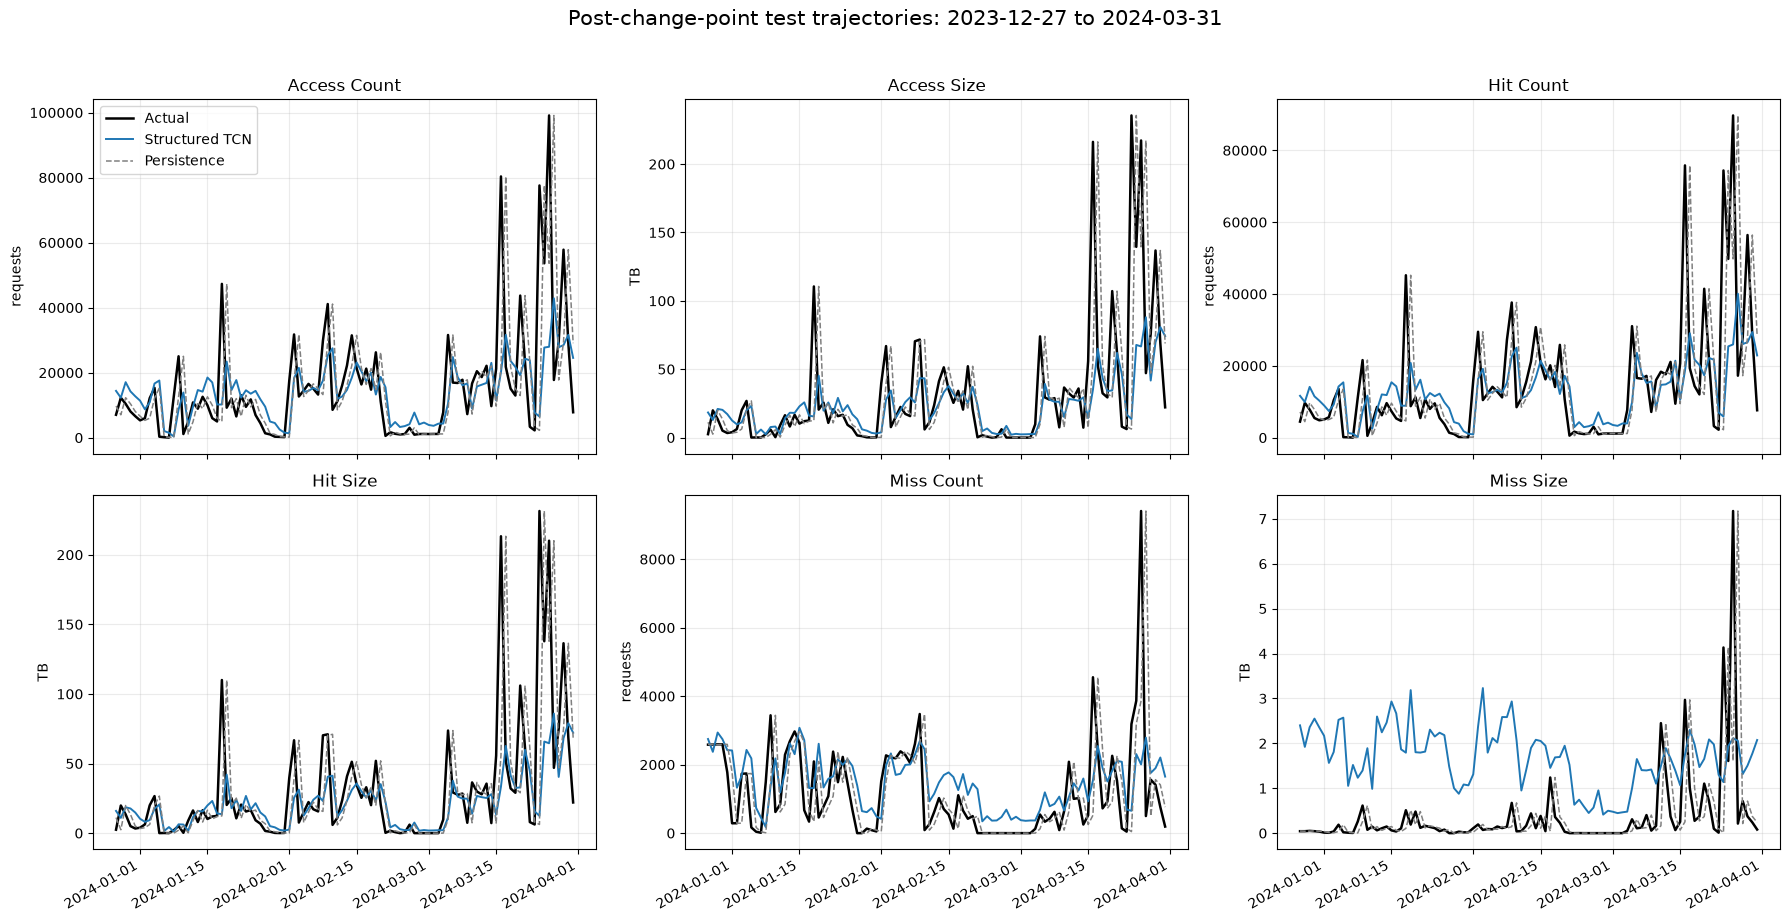

In [ ]:
output_dir = Path('results') / 'post_change_point_structured_14day_5block_64channel'
predictions = pd.read_csv(output_dir / 'predictions.csv', index_col='target_date', parse_dates=True)
feature_names = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
units = ['requests', 'TB', 'requests', 'TB', 'requests', 'TB']

fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharex=True)
for i, (name, unit, axis) in enumerate(zip(feature_names, units, axes.flat)):
    axis.plot(predictions.index, predictions[f'{name}_actual'], color='black', linewidth=1.8, label='Actual')
    axis.plot(predictions.index, predictions[f'{name}_predicted'], color='#1f77b4', linewidth=1.4, label='Structured TCN')
    axis.plot(predictions.index, predictions[f'{name}_persistence'], color='gray', linewidth=1.1, linestyle='--', label='Persistence')
    axis.set_title(name.replace('_', ' ').title())
    axis.set_ylabel(unit)
    axis.grid(alpha=0.25)
    if i == 0: axis.legend()
fig.suptitle('Post-change-point test trajectories: 2023-12-27 to 2024-03-31', y=1.02, fontsize=15)
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(output_dir / 'test_trajectories.png', dpi=200, bbox_inches='tight')
plt.show()


### 5. Compare RMSE improvement over persistence

Positive values indicate that the Structured TCN improves on persistence; negative values indicate worse RMSE. This percentage comparison keeps count and size variables separate from their original units.


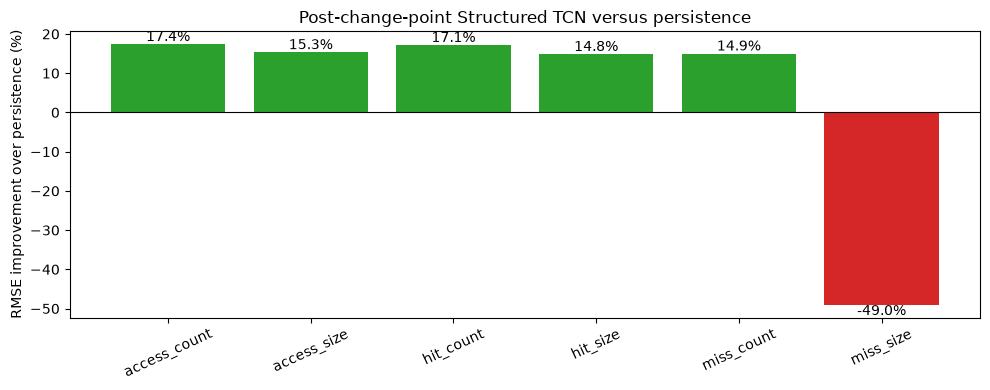

In [5]:
rmse_results = pd.read_csv(output_dir / 'test_rmse.csv', index_col=0)
improvement = 100 * (1 - rmse_results['Structured TCN RMSE'] / rmse_results['Persistence RMSE'])
colors = ['#2ca02c' if value >= 0 else '#d62728' for value in improvement]
fig, axis = plt.subplots(figsize=(10, 4))
axis.bar(improvement.index, improvement.values, color=colors)
axis.axhline(0, color='black', linewidth=0.8)
axis.set_ylabel('RMSE improvement over persistence (%)')
axis.set_title('Post-change-point Structured TCN versus persistence')
axis.tick_params(axis='x', rotation=25)
for bar, value in zip(axis.patches, improvement.values):
    axis.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.1f}%', ha='center', va='bottom' if value >= 0 else 'top')
fig.tight_layout()
fig.savefig(output_dir / 'rmse_improvement_over_persistence.png', dpi=200, bbox_inches='tight')
plt.show()


### 6. Alternative checkpoint selection: validation miss_size RMSE

This experiment keeps the post-change-point data, model architecture, structured loss, and random seed fixed. Only the early-stopping selection metric changes from validation `hit_size` RMSE to validation `miss_size` RMSE. This isolates the trade-off caused by selecting a checkpoint for miss-size accuracy.


Selected epoch: 15; validation miss_size RMSE: 1.1011 TB


,hit_size-selected RMSE,miss_size-selected RMSE,Persistence RMSE,Unit
access_count,15799.924121,16220.274298,19116.796875,requests
access_size,40.534954,40.826150,47.844620,TB
hit_count,14847.777690,15247.190807,17914.582031,requests
hit_size,40.039870,40.275911,47.000496,TB
miss_count,1261.513121,1233.518340,1482.898804,requests
miss_size,1.722312,1.223160,1.156154,TB


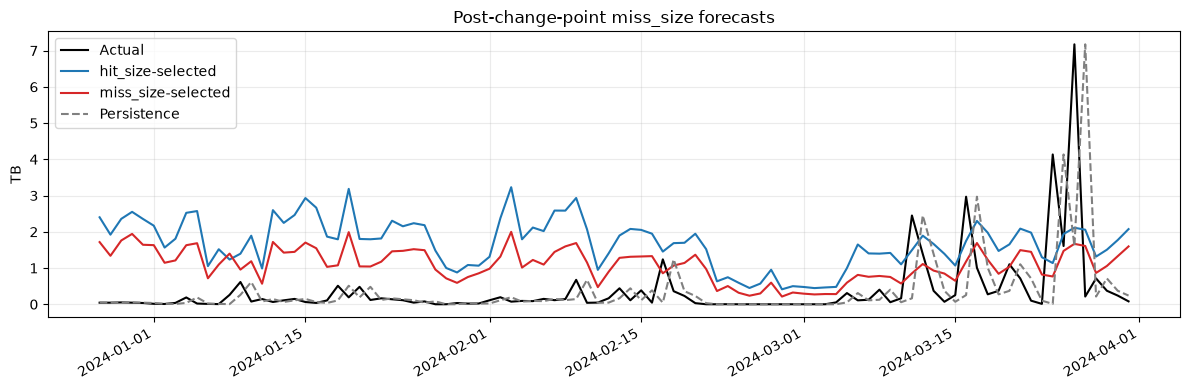

Saved miss_size-selection comparison to: /Users/dengyingxin/Desktop/xcache/week4/results/post_change_point_structured_14day_5block_64channel_select_miss_size


In [6]:
# Required first: run the setup and five-block Structured TCN training cells above.
MISS_SELECTION_INDEX = FEATURE_NAMES.index('miss_size')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
miss_selected_model = StructuredTCN().to(device)
miss_optimizer = torch.optim.Adam(miss_selected_model.parameters(), lr=LEARNING_RATE)
miss_train_loader = make_loader(features[train_mask], labels[train_mask], shuffle=True)
best_miss_rmse, best_miss_state, best_miss_epoch, stale, miss_history_rows = float('inf'), None, 0, 0, []
for epoch in range(1, MAX_EPOCHS + 1):
    miss_selected_model.train(); losses = []
    for xb, yb in miss_train_loader:
        miss_optimizer.zero_grad()
        loss = structured_loss(miss_selected_model(xb.to(device)), yb.to(device))
        loss.backward(); miss_optimizer.step(); losses.append(loss.item())
    validation_prediction = predict_original(miss_selected_model, features[validation_mask])
    validation_miss_rmse = float(np.sqrt(np.mean((validation_prediction[:, MISS_SELECTION_INDEX] - validation_actual[:, MISS_SELECTION_INDEX]) ** 2)))
    miss_history_rows.append({'epoch': epoch, 'training_structured_loss': np.mean(losses), 'validation_miss_size_rmse': validation_miss_rmse})
    if validation_miss_rmse < best_miss_rmse:
        best_miss_rmse, best_miss_state, best_miss_epoch, stale = validation_miss_rmse, copy.deepcopy(miss_selected_model.state_dict()), epoch, 0
    else:
        stale += 1
    if stale >= PATIENCE:
        break
miss_selected_model.load_state_dict(best_miss_state)
miss_history = pd.DataFrame(miss_history_rows)
print(f'Selected epoch: {best_miss_epoch}; validation miss_size RMSE: {best_miss_rmse:.4f} TB')

miss_test_prediction = predict_original(miss_selected_model, features[test_mask])
miss_test_rmse = np.sqrt(np.mean((miss_test_prediction - test_actual) ** 2, axis=0))
baseline_results = pd.read_csv(output_dir / 'test_rmse.csv', index_col=0)
comparison = pd.DataFrame({'hit_size-selected RMSE': baseline_results['Structured TCN RMSE'], 'miss_size-selected RMSE': miss_test_rmse, 'Persistence RMSE': persistence_rmse, 'Unit': baseline_results['Unit']}, index=FEATURE_NAMES)
display(comparison)

miss_output_dir = Path('results') / 'post_change_point_structured_14day_5block_64channel_select_miss_size'
miss_output_dir.mkdir(parents=True, exist_ok=True)
miss_history.to_csv(miss_output_dir / 'history.csv', index=False)
comparison.to_csv(miss_output_dir / 'test_rmse_comparison.csv')
miss_predictions = pd.DataFrame(index=df.index[positions[test_mask]]); miss_predictions.index.name = 'target_date'
for i, name in enumerate(FEATURE_NAMES):
    miss_predictions[f'{name}_actual'] = test_actual[:, i]
    miss_predictions[f'{name}_predicted'] = miss_test_prediction[:, i]
    miss_predictions[f'{name}_persistence'] = persistence[:, i]
miss_predictions.to_csv(miss_output_dir / 'predictions.csv')

fig, axis = plt.subplots(figsize=(12, 4))
test_dates = df.index[positions[test_mask]]
axis.plot(test_dates, test_actual[:, MISS_SELECTION_INDEX], color='black', label='Actual')
axis.plot(test_dates, test_prediction[:, MISS_SELECTION_INDEX], color='#1f77b4', label='hit_size-selected')
axis.plot(test_dates, miss_test_prediction[:, MISS_SELECTION_INDEX], color='#d62728', label='miss_size-selected')
axis.plot(test_dates, persistence[:, MISS_SELECTION_INDEX], color='gray', linestyle='--', label='Persistence')
axis.set(title='Post-change-point miss_size forecasts', ylabel='TB')
axis.legend(); axis.grid(alpha=0.25); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(miss_output_dir / 'miss_size_trajectory_comparison.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved miss_size-selection comparison to:', miss_output_dir.resolve())


### 7. Calendar-feature Structured TCN

The TCN blocks, lookback, channels, split, and structured loss remain unchanged. Known target-day calendar covariates are added only to the output head: day-of-week one-hot encoding, cyclic month encoding, and a weekend indicator. These calendar values are known when forecasting the next day and therefore do not leak future XCache observations.


In [7]:
# Required first: run the data setup and baseline model cells above.
target_dates = df.index[positions]
day_of_week = target_dates.dayofweek.to_numpy()
day_of_week_one_hot = np.eye(7, dtype=np.float32)[day_of_week]
month_angle = 2 * np.pi * (target_dates.month.to_numpy() - 1) / 12
month_features = np.column_stack([np.sin(month_angle), np.cos(month_angle)]).astype(np.float32)
weekend_indicator = (day_of_week >= 5).astype(np.float32).reshape(-1, 1)
calendar_features = np.column_stack([day_of_week_one_hot, month_features, weekend_indicator]).astype(np.float32)
CALENDAR_FEATURE_COUNT = calendar_features.shape[1]
print('Calendar features:', CALENDAR_FEATURE_COUNT, '(7 day-of-week + 2 month + 1 weekend)')

class StructuredTCNWithCalendar(nn.Module):
    def __init__(self):
        super().__init__(); blocks, in_channels = [], 4
        for level, out_channels in enumerate(CHANNELS):
            blocks.append(TemporalBlock(in_channels, out_channels, 2 ** level)); in_channels = out_channels
        self.tcn = nn.Sequential(*blocks)
        self.output = nn.Linear(CHANNELS[-1] + CALENDAR_FEATURE_COUNT, 4)
    def forward(self, x, calendar):
        hidden = self.tcn(x)[:, :, -1]
        output = self.output(torch.cat([hidden, calendar], dim=1)).unsqueeze(1)
        return torch.cat([output[:, :, :2], torch.sigmoid(output[:, :, 2:])], dim=2)

def make_calendar_loader(x, calendar, y, shuffle=False):
    x_tensor = torch.tensor(x.transpose(0, 2, 1).tolist(), dtype=torch.float32)
    calendar_tensor = torch.tensor(calendar.tolist(), dtype=torch.float32)
    y_tensor = torch.tensor(y.tolist(), dtype=torch.float32)
    return DataLoader(TensorDataset(x_tensor, calendar_tensor, y_tensor), batch_size=BATCH_SIZE, shuffle=shuffle)

def predict_calendar_model(model_run, x, calendar):
    model_run.eval(); outputs = []
    with torch.no_grad():
        for start in range(0, len(x), BATCH_SIZE):
            x_tensor = torch.tensor(x[start:start + BATCH_SIZE].transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
            calendar_tensor = torch.tensor(calendar[start:start + BATCH_SIZE].tolist(), dtype=torch.float32).to(device)
            outputs.append(np.asarray(model_run(x_tensor, calendar_tensor).cpu().tolist(), dtype=np.float64))
    output = np.concatenate(outputs)[:, 0, :]
    access = np.maximum(np.expm1(log_target_scaler.inverse_transform(output[:, :2])), 0); ratios = np.clip(output[:, 2:], 0, 1)
    return np.column_stack([access[:, 0], access[:, 1], access[:, 0] * ratios[:, 0], access[:, 1] * ratios[:, 1], access[:, 0] * (1 - ratios[:, 0]), access[:, 1] * (1 - ratios[:, 1])])

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
calendar_model = StructuredTCNWithCalendar().to(device)
calendar_optimizer = torch.optim.Adam(calendar_model.parameters(), lr=LEARNING_RATE)
calendar_train_loader = make_calendar_loader(features[train_mask], calendar_features[train_mask], labels[train_mask], shuffle=True)
best_calendar_rmse, best_calendar_state, best_calendar_epoch, stale, calendar_history_rows = float('inf'), None, 0, 0, []
for epoch in range(1, MAX_EPOCHS + 1):
    calendar_model.train(); losses = []
    for xb, cb, yb in calendar_train_loader:
        calendar_optimizer.zero_grad()
        loss = structured_loss(calendar_model(xb.to(device), cb.to(device)), yb.to(device))
        loss.backward(); calendar_optimizer.step(); losses.append(loss.item())
    validation_prediction = predict_calendar_model(calendar_model, features[validation_mask], calendar_features[validation_mask])
    validation_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_SELECTION_INDEX] - validation_actual[:, PRIMARY_SELECTION_INDEX]) ** 2)))
    calendar_history_rows.append({'epoch': epoch, 'training_structured_loss': np.mean(losses), 'validation_hit_size_rmse': validation_rmse})
    if validation_rmse < best_calendar_rmse:
        best_calendar_rmse, best_calendar_state, best_calendar_epoch, stale = validation_rmse, copy.deepcopy(calendar_model.state_dict()), epoch, 0
    else:
        stale += 1
    if stale >= PATIENCE:
        break
calendar_model.load_state_dict(best_calendar_state)
calendar_history = pd.DataFrame(calendar_history_rows)
print(f'Selected epoch: {best_calendar_epoch}; validation hit_size RMSE: {best_calendar_rmse:.4f} TB')

calendar_test_prediction = predict_calendar_model(calendar_model, features[test_mask], calendar_features[test_mask])
calendar_test_actual = raw_values[positions[test_mask]]
calendar_persistence = raw_values[positions[test_mask] - 1]
calendar_test_rmse = np.sqrt(np.mean((calendar_test_prediction - calendar_test_actual) ** 2, axis=0))
calendar_persistence_rmse = np.sqrt(np.mean((calendar_persistence - calendar_test_actual) ** 2, axis=0))
baseline_results = pd.read_csv(output_dir / 'test_rmse.csv', index_col=0)
calendar_comparison = pd.DataFrame({'Baseline Structured TCN RMSE': baseline_results['Structured TCN RMSE'], 'Calendar-feature TCN RMSE': calendar_test_rmse, 'Persistence RMSE': calendar_persistence_rmse, 'Unit': baseline_results['Unit']}, index=FEATURE_NAMES)
display(calendar_comparison)

calendar_output_dir = Path('results') / 'post_change_point_structured_14day_5block_64channel_calendar'
calendar_output_dir.mkdir(parents=True, exist_ok=True)
calendar_history.to_csv(calendar_output_dir / 'history.csv', index=False)
calendar_comparison.to_csv(calendar_output_dir / 'test_rmse_comparison.csv')
calendar_predictions = pd.DataFrame(index=target_dates[test_mask]); calendar_predictions.index.name = 'target_date'
for i, name in enumerate(FEATURE_NAMES):
    calendar_predictions[f'{name}_actual'] = calendar_test_actual[:, i]
    calendar_predictions[f'{name}_predicted'] = calendar_test_prediction[:, i]
    calendar_predictions[f'{name}_persistence'] = calendar_persistence[:, i]
calendar_predictions.to_csv(calendar_output_dir / 'predictions.csv')
print('Saved calendar-feature results to:', calendar_output_dir.resolve())


Calendar features: 10 (7 day-of-week + 2 month + 1 weekend)
Selected epoch: 26; validation hit_size RMSE: 19.1744 TB


,Baseline Structured TCN RMSE,Calendar-feature TCN RMSE,Persistence RMSE,Unit
access_count,15799.924121,16289.618335,19116.796875,requests
access_size,40.534954,41.066928,47.844620,TB
hit_count,14847.777690,15375.468784,17914.582031,requests
hit_size,40.039870,40.436360,47.000496,TB
miss_count,1261.513121,1248.200167,1482.898804,requests
miss_size,1.722312,1.582565,1.156154,TB


Saved calendar-feature results to: /Users/dengyingxin/Desktop/xcache/week4/results/post_change_point_structured_14day_5block_64channel_calendar


### 8. Calendar-feature ablation study

To identify whether a particular calendar signal is useful, this experiment holds the TCN architecture, 14-day lookback, chronological split, structured loss, optimizer, and random seed fixed. Each candidate changes only the calendar covariates supplied to the output head. Checkpoints are selected exclusively by validation `hit_size` RMSE; the test period is not used to choose a candidate.

The candidates are: no calendar covariates, day-of-week only, annual seasonality only, day-of-week plus annual seasonality, and weekend only. The weekend indicator is intentionally evaluated separately because it overlaps with day-of-week information.

In [9]:
# Required first: run the data setup and model-definition cells above.
# This cell uses validation hit_size RMSE only; it does not evaluate candidates on the test set.
# It defines its own calendar arrays and helpers, so Section 7 does not need to be rerun.
target_dates = df.index[positions]
day_of_week = target_dates.dayofweek.to_numpy()
day_of_week_one_hot = np.eye(7, dtype=np.float32)[day_of_week]
month_angle = 2 * np.pi * (target_dates.month.to_numpy() - 1) / 12
month_features = np.column_stack([np.sin(month_angle), np.cos(month_angle)]).astype(np.float32)
weekend_indicator = (day_of_week >= 5).astype(np.float32).reshape(-1, 1)

def make_calendar_loader(x, calendar, y, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(x.transpose(0, 2, 1).tolist(), dtype=torch.float32), torch.tensor(calendar.tolist(), dtype=torch.float32), torch.tensor(y.tolist(), dtype=torch.float32)), batch_size=BATCH_SIZE, shuffle=shuffle)

def predict_calendar_model(model_run, x, calendar):
    model_run.eval(); outputs = []
    with torch.no_grad():
        for start in range(0, len(x), BATCH_SIZE):
            x_tensor = torch.tensor(x[start:start + BATCH_SIZE].transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
            calendar_tensor = torch.tensor(calendar[start:start + BATCH_SIZE].tolist(), dtype=torch.float32).to(device)
            outputs.append(np.asarray(model_run(x_tensor, calendar_tensor).cpu().tolist(), dtype=np.float64))
    output = np.concatenate(outputs)[:, 0, :]
    access = np.maximum(np.expm1(log_target_scaler.inverse_transform(output[:, :2])), 0); ratios = np.clip(output[:, 2:], 0, 1)
    return np.column_stack([access[:, 0], access[:, 1], access[:, 0] * ratios[:, 0], access[:, 1] * ratios[:, 1], access[:, 0] * (1 - ratios[:, 0]), access[:, 1] * (1 - ratios[:, 1])])

calendar_sets = {
    'No calendar features': np.empty((len(target_dates), 0), dtype=np.float32),
    'Day of week only': day_of_week_one_hot,
    'Annual seasonality only': month_features,
    'Day of week + annual seasonality': np.column_stack([day_of_week_one_hot, month_features]).astype(np.float32),
    'All calendar features': np.column_stack([day_of_week_one_hot, month_features, weekend_indicator]).astype(np.float32),
    'Weekend only': weekend_indicator,
}

class StructuredTCNWithSelectedCalendar(nn.Module):
    def __init__(self, n_calendar_features):
        super().__init__(); blocks, in_channels = [], 4
        for level, out_channels in enumerate(CHANNELS):
            blocks.append(TemporalBlock(in_channels, out_channels, 2 ** level)); in_channels = out_channels
        self.tcn = nn.Sequential(*blocks)
        self.output = nn.Linear(CHANNELS[-1] + n_calendar_features, 4)
        self.n_calendar_features = n_calendar_features
    def forward(self, x, calendar):
        hidden = self.tcn(x)[:, :, -1]
        output = self.output(torch.cat([hidden, calendar], dim=1)).unsqueeze(1)
        return torch.cat([output[:, :, :2], torch.sigmoid(output[:, :, 2:])], dim=2)

def run_calendar_ablation(name, candidate_features):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model_run = StructuredTCNWithSelectedCalendar(candidate_features.shape[1]).to(device)
    optimizer_run = torch.optim.Adam(model_run.parameters(), lr=LEARNING_RATE)
    train_loader_run = make_calendar_loader(features[train_mask], candidate_features[train_mask], labels[train_mask], shuffle=True)
    best_rmse_run, best_state_run, best_epoch_run, stale_run = float('inf'), None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model_run.train()
        for xb, cb, yb in train_loader_run:
            optimizer_run.zero_grad()
            loss = structured_loss(model_run(xb.to(device), cb.to(device)), yb.to(device))
            loss.backward(); optimizer_run.step()
        prediction_run = predict_calendar_model(model_run, features[validation_mask], candidate_features[validation_mask])
        rmse_run = float(np.sqrt(np.mean((prediction_run[:, PRIMARY_SELECTION_INDEX] - validation_actual[:, PRIMARY_SELECTION_INDEX]) ** 2)))
        if rmse_run < best_rmse_run:
            best_rmse_run, best_state_run, best_epoch_run, stale_run = rmse_run, copy.deepcopy(model_run.state_dict()), epoch, 0
        else:
            stale_run += 1
        if stale_run >= PATIENCE:
            break
    model_run.load_state_dict(best_state_run)
    test_prediction_run = predict_calendar_model(model_run, features[test_mask], candidate_features[test_mask])
    test_actual_run = raw_values[positions[test_mask]]
    test_rmse_run = np.sqrt(np.mean((test_prediction_run - test_actual_run) ** 2, axis=0))
    summary_row = {'calendar_feature_set': name, 'n_calendar_features': candidate_features.shape[1], 'best_epoch': best_epoch_run, 'validation_hit_size_rmse': best_rmse_run}
    test_rows = [{'calendar_feature_set': name, 'variable': variable, 'test_rmse': rmse, 'unit': 'requests' if 'count' in variable else 'TB'} for variable, rmse in zip(FEATURE_NAMES, test_rmse_run)]
    return summary_row, test_rows

ablation_rows, calendar_ablation_test_rows = [], []
for name, candidate_features in calendar_sets.items():
    print(f'Running: {name} ({candidate_features.shape[1]} features)')
    summary_row, test_rows = run_calendar_ablation(name, candidate_features)
    ablation_rows.append(summary_row); calendar_ablation_test_rows.extend(test_rows)
calendar_ablation_results = pd.DataFrame(ablation_rows).sort_values('validation_hit_size_rmse').reset_index(drop=True)
display(calendar_ablation_results)

week4_dir = Path.cwd() if (Path.cwd() / 'Sammy_TCN_260930.ipynb').exists() else Path.cwd() / 'week4'
ablation_output_dir = week4_dir / 'results' / 'post_change_point_calendar_ablation'
ablation_output_dir.mkdir(parents=True, exist_ok=True)
calendar_ablation_results.to_csv(ablation_output_dir / 'validation_hit_size_ablation.csv', index=False)
calendar_ablation_test_results = pd.DataFrame(calendar_ablation_test_rows)
calendar_ablation_test_results.to_csv(ablation_output_dir / 'test_rmse_by_feature_set.csv', index=False)
persistence_test_rmse = np.sqrt(np.mean((raw_values[positions[test_mask] - 1] - raw_values[positions[test_mask]]) ** 2, axis=0))
calendar_ablation_test_table = calendar_ablation_test_results.pivot(index='variable', columns='calendar_feature_set', values='test_rmse').reindex(FEATURE_NAMES)
calendar_ablation_test_table['Persistence'] = persistence_test_rmse
calendar_ablation_test_table['Unit'] = ['requests' if 'count' in variable else 'TB' for variable in FEATURE_NAMES]
display(calendar_ablation_test_table)
calendar_ablation_test_table.to_csv(ablation_output_dir / 'test_rmse_comparison.csv')
print('Saved validation and held-out test comparisons to:', ablation_output_dir.resolve())


Running: No calendar features (0 features)
Running: Day of week only (7 features)
Running: Annual seasonality only (2 features)
Running: Day of week + annual seasonality (9 features)
Running: All calendar features (10 features)
Running: Weekend only (1 features)


,calendar_feature_set,n_calendar_features,best_epoch,validation_hit_size_rmse
0,Day of week + annual seasonality,9,1,18.490622
1,Weekend only,1,1,18.681583
2,Day of week only,7,1,18.858137
3,No calendar features,0,9,18.979439
4,All calendar features,10,26,19.174371
5,Annual seasonality only,2,4,19.545999


calendar_feature_set,All calendar features,Annual seasonality only,Day of week + annual seasonality,Day of week only,No calendar features,Weekend only,Persistence,Unit
variable,,,,,,,,
access_count,16289.618335,16843.644065,15469.627097,17011.502074,15799.924121,18418.899552,19116.796875,requests
access_size,41.066928,39.845386,41.383090,40.461184,40.534954,40.198686,47.844620,TB
hit_count,15375.468784,15419.607469,14551.913610,15582.027882,14847.777690,17356.009071,17914.582031,requests
hit_size,40.436360,38.993261,41.548251,40.306083,40.039870,39.962685,47.000496,TB
miss_count,1248.200167,2070.229165,1496.432614,1922.712683,1261.513121,1403.626018,1482.898804,requests
miss_size,1.582565,3.073271,3.166167,3.062207,1.722312,2.181065,1.156154,TB


Saved validation and held-out test comparisons to: /Users/dengyingxin/Desktop/xcache/week4/results/post_change_point_calendar_ablation
